In [1]:
import pickle
from collections import defaultdict

import numpy as np
import pandas as pd
import faiss
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

from utils import *

In [2]:
interactions = pd.read_csv(
    "data/train.csv",
    names=['USER_ID', 'VIDEO_ID', 'INTERACTION_TYPE', 'TIMESTAMP'],
    header=None
)

In [3]:
interactions = interactions.dropna(
    subset=['USER_ID', 'VIDEO_ID', 'INTERACTION_TYPE', 'TIMESTAMP']
)

In [4]:
interactions['USER_ID'] = interactions['USER_ID'].astype("Int64")
interactions['VIDEO_ID'] = interactions['VIDEO_ID'].astype("Int64")
interactions['INTERACTION_TYPE'] = interactions['INTERACTION_TYPE'].astype("Int64")
interactions['TIMESTAMP'] = pd.to_datetime(interactions['TIMESTAMP'], unit="s", utc=True)

In [5]:
pd.concat([interactions.head(), interactions.tail()])

,USER_ID,VIDEO_ID,INTERACTION_TYPE,TIMESTAMP
0,1,46763,0,2017-01-09 19:50:16+00:00
1,1,173483,0,2017-01-09 19:47:42+00:00
2,1,284109,0,2017-01-09 19:50:16+00:00
3,1,331777,0,2017-01-09 19:50:16+00:00
4,1,379208,0,2017-01-09 19:47:42+00:00
19433732,1483626,34633,5,2017-01-24 13:00:24+00:00
19433733,1483626,91594,5,2017-01-24 13:00:24+00:00
19433734,1485180,640382,5,2016-12-27 14:59:44+00:00
19433735,1490693,124350,5,2017-01-18 07:01:59+00:00
19433736,1490693,472666,5,2017-01-18 07:01:59+00:00


In [6]:
interactions.shape

(19433737, 4)

In [7]:
interactions = interactions[interactions['INTERACTION_TYPE'].isin([1, 2, 3, 5])]

interactions = interactions.drop(['INTERACTION_TYPE'], axis=1)

In [8]:
interactions.shape

(3729257, 3)

In [9]:
user_ids = interactions['USER_ID'].unique().tolist()

rng = np.random.default_rng(RANDOM_STATE)

user_ids = rng.permutation(user_ids).tolist()

split_idx = int(len(user_ids) * (1 - VAL_SIZE))

train_user_ids = user_ids[:split_idx]
val_user_ids = user_ids[split_idx:]

train_interactions = interactions[interactions['USER_ID'].isin(train_user_ids)].copy()
val_interactions = interactions[interactions['USER_ID'].isin(val_user_ids)].copy()

In [10]:
train_interactions.shape, val_interactions.shape

((2502005, 3), (1227252, 3))

In [11]:
train_interactions = train_interactions.sort_values(['USER_ID', 'TIMESTAMP'])

train_interactions['VIDEO_ID_SEQ'] = train_interactions.groupby(['USER_ID'])['VIDEO_ID'].transform(
    lambda video_id_series: [
        video_id_series.iloc[:idx].tolist()[-MAX_SEQ_LEN:]
        for idx in range(len(video_id_series))
    ]
)

In [12]:
val_interactions = val_interactions.sort_values(['USER_ID', 'TIMESTAMP'])

val_interactions['VIDEO_ID_SEQ'] = val_interactions.groupby(['USER_ID'])['VIDEO_ID'].transform(
    lambda video_id_series: [
        video_id_series.iloc[:idx].tolist()[-MAX_SEQ_LEN:]
        for idx in range(len(video_id_series))
    ]
)

In [13]:
pd.concat([train_interactions.head(), train_interactions.tail()])

,USER_ID,VIDEO_ID,TIMESTAMP,VIDEO_ID_SEQ
15704490,4,360712,2016-11-07 19:51:07+00:00,[]
15704492,4,417897,2016-11-10 15:21:21+00:00,[360712]
15704499,4,743981,2016-11-15 11:52:01+00:00,"[360712, 417897]"
15704485,4,171061,2016-11-16 10:01:06+00:00,"[360712, 417897, 743981]"
19193622,4,1304931,2016-11-18 12:45:28+00:00,"[360712, 417897, 743981, 171061]"
19193610,1497014,820673,2017-01-24 08:44:27+00:00,"[1296299, 131352, 1293024, 55677, 389888, 7566..."
19193603,1497014,425607,2017-01-24 22:06:44+00:00,"[1296299, 131352, 1293024, 55677, 389888, 7566..."
19193618,1497015,273817,2017-01-05 13:12:34+00:00,[]
19193620,1497018,1003535,2016-11-17 09:01:53+00:00,[]
19193619,1497018,789481,2017-01-19 12:33:53+00:00,[1003535]


In [14]:
train_interactions.shape

(2502005, 4)

In [15]:
video_id_counts = train_interactions['VIDEO_ID'].value_counts()

video_id_probas = video_id_counts / video_id_counts.sum()

video_id_probas = {
    int(video_id): float(proba)
    for video_id, proba in video_id_probas.items()
}

In [16]:
video_ids = train_interactions['VIDEO_ID'].unique().tolist()

for video_id_seq in train_interactions['VIDEO_ID_SEQ']:
    video_ids.extend(video_id_seq)

video_ids = sorted(list(set(video_ids)))

In [17]:
videos_crd = len(video_ids) + 3

In [18]:
video_id_to_video_idx = {
    str(video_id): video_idx + 3
    for video_idx, video_id in enumerate(video_ids)
}

with open(VIDEO_ID_TO_VIDEO_IDX_PATH, "wb") as file:
    pickle.dump(video_id_to_video_idx, file)

In [19]:
video_idx_to_video_id = {
    str(video_idx + 3): video_id
    for video_idx, video_id in enumerate(video_ids)
}

with open(VIDEO_IDX_TO_VIDEO_ID_PATH, "wb") as file:
    pickle.dump(video_idx_to_video_id, file)

In [20]:
video_idx_probas = {
    video_id_to_video_idx[str(video_id)]: proba
    for video_id, proba in video_id_probas.items()
}

In [21]:
train_interactions['VIDEO_IDX'] = train_interactions['VIDEO_ID'].map(
    lambda video_id:
    video_id_to_video_idx[str(video_id)]
)
train_interactions = train_interactions.drop(['VIDEO_ID'], axis=1)

train_interactions['VIDEO_IDX_SEQ'] = train_interactions['VIDEO_ID_SEQ'].map(
    lambda video_id_seq: [
        video_id_to_video_idx[str(video_id)]
        for video_id in video_id_seq
    ] if video_id_seq else [BGN_IDX]
)
train_interactions = train_interactions.drop(['VIDEO_ID_SEQ'], axis=1)

train_interactions['VIDEO_IDX_SEQ_LEN'] = train_interactions['VIDEO_IDX_SEQ'].map(
    lambda video_idx_seq:
    len(video_idx_seq)
)

In [22]:
val_interactions['VIDEO_IDX'] = val_interactions['VIDEO_ID'].map(
    lambda video_id:
    video_id_to_video_idx.get(str(video_id), UNK_IDX)
)
val_interactions = val_interactions.drop(['VIDEO_ID'], axis=1)

val_interactions['VIDEO_IDX_SEQ'] = val_interactions['VIDEO_ID_SEQ'].map(
    lambda video_id_seq: [
        video_id_to_video_idx.get(str(video_id), UNK_IDX)
        for video_id in video_id_seq
    ] if video_id_seq else [BGN_IDX]
)
val_interactions = val_interactions.drop(['VIDEO_ID_SEQ'], axis=1)

val_interactions['VIDEO_IDX_SEQ_LEN'] = val_interactions['VIDEO_IDX_SEQ'].map(
    lambda video_idx_seq:
    len(video_idx_seq)
)

In [23]:
pd.concat([train_interactions.head(), train_interactions.tail()])

,USER_ID,TIMESTAMP,VIDEO_IDX,VIDEO_IDX_SEQ,VIDEO_IDX_SEQ_LEN
15704490,4,2016-11-07 19:51:07+00:00,92008,[2],1
15704492,4,2016-11-10 15:21:21+00:00,106896,[92008],1
15704499,4,2016-11-15 11:52:01+00:00,190558,"[92008, 106896]",2
15704485,4,2016-11-16 10:01:06+00:00,43560,"[92008, 106896, 190558]",3
19193622,4,2016-11-18 12:45:28+00:00,334716,"[92008, 106896, 190558, 43560]",4
19193610,1497014,2017-01-24 08:44:27+00:00,210379,"[332466, 33354, 331673, 14076, 99552, 193902, ...",22
19193603,1497014,2017-01-24 22:06:44+00:00,108872,"[332466, 33354, 331673, 14076, 99552, 193902, ...",23
19193618,1497015,2017-01-05 13:12:34+00:00,69880,[2],1
19193620,1497018,2016-11-17 09:01:53+00:00,257445,[2],1
19193619,1497018,2017-01-19 12:33:53+00:00,202244,[257445],1


In [24]:
train_interactions.shape

(2502005, 5)

In [25]:
train_dataset = DatasetForTraining(
    interactions=train_interactions,
    video_idx_probas=video_idx_probas,
    random_state=RANDOM_STATE
)

val_dataset = DatasetForTraining(
    interactions=val_interactions,
    video_idx_probas=video_idx_probas,
    random_state=RANDOM_STATE
)

In [26]:
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed(RANDOM_STATE)

In [27]:
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    collate_fn=training_collate_fn,
    pin_memory=True,
    persistent_workers=True
)

val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    collate_fn=training_collate_fn,
    pin_memory=True,
    persistent_workers=True
)

In [28]:
user_encoder_kwargs = {
    "videos_crd": videos_crd,
    "d_model": D_MODEL,
    "pad_idx": PAD_IDX,
    "gru_num_layers": GRU_NUM_LAYERS,
    "dropout": DROPOUT
}

with open(USER_ENCODER_KWARGS_PATH, "wb") as file:
    pickle.dump(user_encoder_kwargs, file)

In [29]:
video_encoder_kwargs = {
    "videos_crd": videos_crd,
    "d_model": D_MODEL,
    "pad_idx": PAD_IDX
}

with open(VIDEO_ENCODER_KWARGS_PATH, "wb") as file:
    pickle.dump(video_encoder_kwargs, file)

In [30]:
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed(RANDOM_STATE)

In [31]:
user_encoder = UserEncoder(**user_encoder_kwargs)

video_encoder = VideoEncoder(**video_encoder_kwargs)

encoders_trainer = EncodersTrainer(
    user_encoder=user_encoder,
    video_encoder=video_encoder
)

In [32]:
print(f"user encoder parameters: {sum(parameters.numel() for parameters in user_encoder.parameters())}")
print(f"video encoder parameters: {sum(parameters.numel() for parameters in video_encoder.parameters())}")
print(f"encoders trainer parameters: {sum(parameters.numel() for parameters in encoders_trainer.parameters())}")

user encoder parameters: 43114240
video encoder parameters: 42883072
encoders trainer parameters: 85997312


In [33]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    params=encoders_trainer.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer=optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [34]:
history = defaultdict(list)
best_val_loss = float("inf")

for epoch in range(EPOCHS):

    print(f"epoch: {epoch + 1}")
    print("-" * 25)

    train_metrics = train_step(
        model=encoders_trainer,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=DEVICE
    )

    val_metrics = val_step(
        model=encoders_trainer,
        dataloader=val_dataloader,
        criterion=criterion,
        device=DEVICE
    )

    train_loss = train_metrics["train_loss"]
    train_hit_10_rate = train_metrics["train_hit_10_rate"]
    train_hit_100_rate = train_metrics["train_hit_100_rate"]
    train_hit_1000_rate = train_metrics["train_hit_1000_rate"]

    val_loss = val_metrics["val_loss"]
    val_hit_10_rate = val_metrics["val_hit_10_rate"]
    val_hit_100_rate = val_metrics["val_hit_100_rate"]
    val_hit_1000_rate = val_metrics["val_hit_1000_rate"]

    scheduler.step(val_loss)

    history["TRAIN_LOSS"].append(train_loss)
    history["TRAIN_HIT_10_RATE"].append(train_hit_10_rate)
    history["TRAIN_HIT_100_RATE"].append(train_hit_100_rate)
    history["TRAIN_HIT_1000_RATE"].append(train_hit_1000_rate)

    history["VAL_LOSS"].append(val_loss)
    history["VAL_HIT_10_RATE"].append(val_hit_10_rate)
    history["VAL_HIT_100_RATE"].append(val_hit_100_rate)
    history["VAL_HIT_1000_RATE"].append(val_hit_1000_rate)

    print(f"train loss: {train_loss:.5f}")
    print(f"val loss: {val_loss:.5f}")

    print(f"train hit@10: {train_hit_10_rate:.2f}")
    print(f"val hit@10: {val_hit_10_rate:.2f}")

    print(f"train hit@100: {train_hit_100_rate:.2f}")
    print(f"val hit@100: {val_hit_100_rate:.2f}")

    print(f"train hit@1000: {train_hit_1000_rate:.2f}")
    print(f"val hit@1000: {val_hit_1000_rate:.2f}")

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(user_encoder.state_dict(), USER_ENCODER_PATH)
        torch.save(video_encoder.state_dict(), VIDEO_ENCODER_PATH)
        torch.save(encoders_trainer.state_dict(), ENCODERS_TRAINER_PATH)

        print("better models saved")
        print("-")

    else:

        print("-")

epoch: 1
-------------------------
train loss: 4.84306
val loss: 3.85420
train hit@10: 0.42
val hit@10: 0.42
train hit@100: 0.45
val hit@100: 0.45
train hit@1000: 0.51
val hit@1000: 0.51
better models saved
-
epoch: 2
-------------------------
train loss: 4.31377
val loss: 3.66506
train hit@10: 0.43
val hit@10: 0.43
train hit@100: 0.47
val hit@100: 0.47
train hit@1000: 0.55
val hit@1000: 0.53
better models saved
-
epoch: 3
-------------------------
train loss: 4.07060
val loss: 3.46900
train hit@10: 0.44
val hit@10: 0.43
train hit@100: 0.50
val hit@100: 0.49
train hit@1000: 0.59
val hit@1000: 0.56
better models saved
-
epoch: 4
-------------------------
train loss: 3.87565
val loss: 3.36724
train hit@10: 0.45
val hit@10: 0.44
train hit@100: 0.52
val hit@100: 0.49
train hit@1000: 0.62
val hit@1000: 0.58
better models saved
-
epoch: 5
-------------------------
train loss: 3.73292
val loss: 3.29339
train hit@10: 0.45
val hit@10: 0.44
train hit@100: 0.53
val hit@100: 0.50
train hit@1000: 0

In [35]:
epochs = range(1, len(history["TRAIN_LOSS"]) + 1)

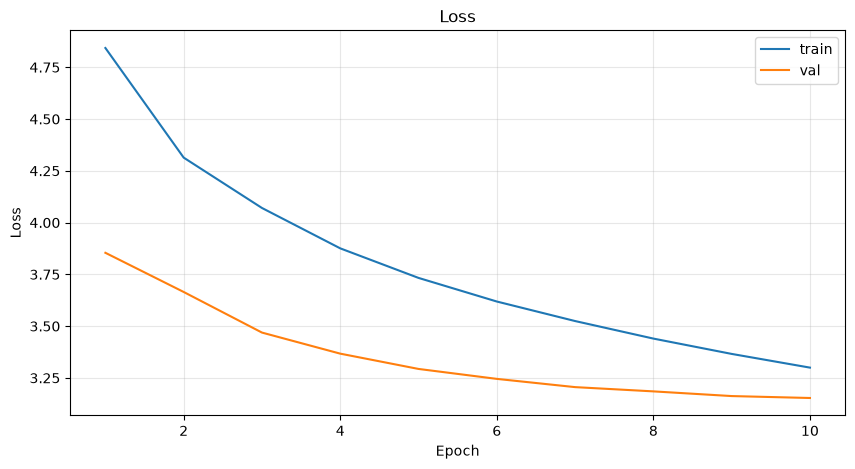

In [36]:
plt.figure(figsize=(10, 5))
plt.plot(epochs, history["TRAIN_LOSS"], label="train")
plt.plot(epochs, history["VAL_LOSS"], label="val")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

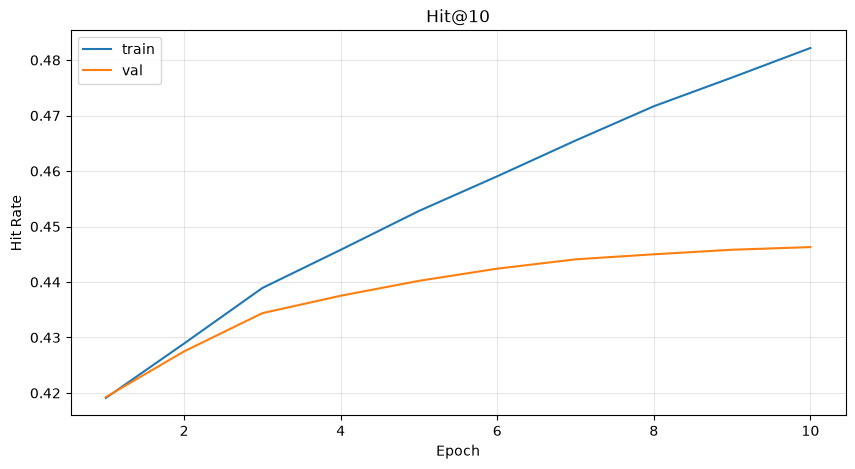

In [37]:
plt.figure(figsize=(10, 5))
plt.plot(epochs, history["TRAIN_HIT_10_RATE"], label="train")
plt.plot(epochs, history["VAL_HIT_10_RATE"], label="val")
plt.xlabel("Epoch")
plt.ylabel("Hit Rate")
plt.title("Hit@10")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

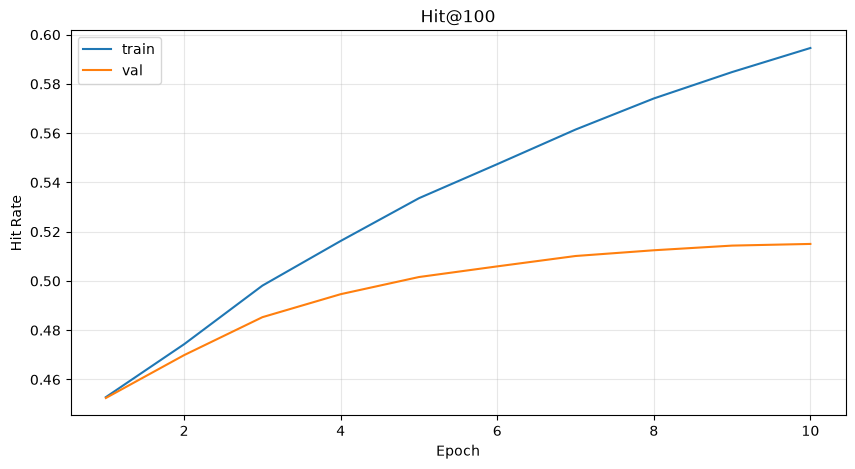

In [38]:
plt.figure(figsize=(10, 5))
plt.plot(epochs, history["TRAIN_HIT_100_RATE"], label="train")
plt.plot(epochs, history["VAL_HIT_100_RATE"], label="val")
plt.xlabel("Epoch")
plt.ylabel("Hit Rate")
plt.title("Hit@100")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

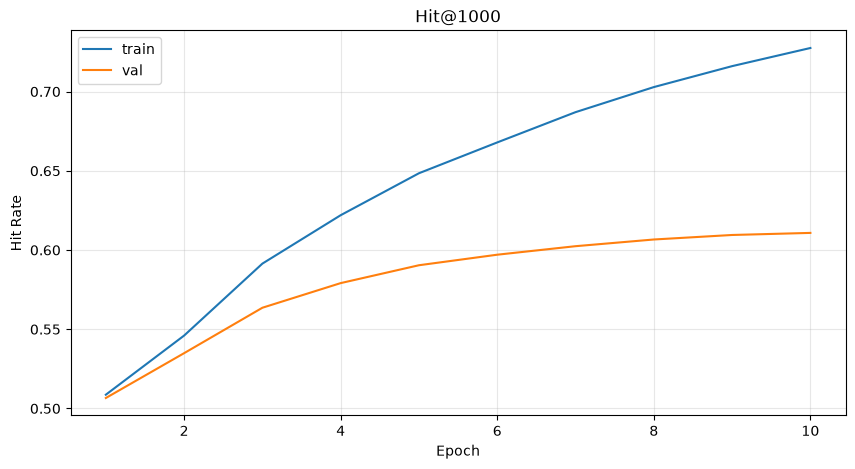

In [39]:
plt.figure(figsize=(10, 5))
plt.plot(epochs, history["TRAIN_HIT_1000_RATE"], label="train")
plt.plot(epochs, history["VAL_HIT_1000_RATE"], label="val")
plt.xlabel("Epoch")
plt.ylabel("Hit Rate")
plt.title("Hit@1000")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [40]:
video_encoder.load_state_dict(torch.load(VIDEO_ENCODER_PATH))

<All keys matched successfully>

In [41]:
video_embeddings = (
    video_encoder.embedding
    .weight[3:].detach().cpu()
    .numpy().astype("float32")
)

video_idxs = np.arange(
    3,
    3 + video_embeddings.shape[0],
    dtype=np.int64
)

In [42]:
video_embeddings_index = faiss.IndexIDMap(
    faiss.IndexFlatIP(video_embeddings.shape[1])
)

In [43]:
video_embeddings_index.add_with_ids(
    video_embeddings,
    video_idxs
)

In [44]:
faiss.write_index(
    video_embeddings_index,
    VIDEO_EMBEDDINGS_INDEX_PATH
)